# 08 — Baseline Thai Lip Reading Training

Baseline แรกสำหรับทดสอบ end-to-end pipeline:

```text
Mouth Frames 96×96
    ↓
Frame CNN Encoder
    ↓
BiGRU Temporal Encoder
    ↓
Linear Classifier
    ↓
CTC Loss
    ↓
Thai Character Sequence
```

Input:
- `dataset/splits/video001/train.csv`
- `dataset/splits/video001/val.csv`
- `dataset/splits/video001/test.csv`

Output:
- `models/lipreading_baseline/best_model.pt`
- `models/lipreading_baseline/last_model.pt`
- `models/lipreading_baseline/charset.json`
- `models/lipreading_baseline/training_history.csv`

## เป้าหมายของรอบแรก

รอบนี้ **ไม่ได้หวังความแม่นสูงทันที** เพราะข้อมูลยังมีเพียง ~33 นาที / 2 speakers

สิ่งที่ต้องการพิสูจน์:
1. Dataset loader อ่าน mouth sequence ได้จริง
2. CTC training ทำงาน
3. Train loss ลด
4. Validation loss ลด
5. Decode อักษรไทยได้
6. คำนวณ CER ได้
7. Model สามารถ overfit subset เล็ก ๆ ได้

## Cell 1 — Environment Check

In [1]:
import sys
import torch

print("=" * 70)
print("ENVIRONMENT")
print("=" * 70)
print("Python :", sys.executable)
print("Version:", sys.version.split()[0])
print("Torch  :", torch.__version__)
print("CUDA   :", torch.cuda.is_available())

if not torch.cuda.is_available():
    raise RuntimeError("Baseline training นี้ควรใช้ CUDA")

DEVICE = torch.device("cuda")

print("GPU    :", torch.cuda.get_device_name(0))
print("VRAM   :", round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2), "GB")

ENVIRONMENT
Python : c:\Users\ASUS FA507NUR\AppData\Local\Programs\Python\Python312\python.exe
Version: 3.12.9
Torch  : 2.6.0+cu124
CUDA   : True
GPU    : NVIDIA GeForce RTX 4050 Laptop GPU
VRAM   : 6.0 GB


## Cell 2 — Path / Config

In [2]:
from pathlib import Path

PROJECT_ROOT = Path(r"D:\Face_detection")
VIDEO_ID = "video001"

SPLIT_ROOT = (
    PROJECT_ROOT
    / "dataset"
    / "splits"
    / VIDEO_ID
)

TRAIN_CSV = SPLIT_ROOT / "train.csv"
VAL_CSV = SPLIT_ROOT / "val.csv"
TEST_CSV = SPLIT_ROOT / "test.csv"

MODEL_ROOT = (
    PROJECT_ROOT
    / "models"
    / "lipreading_baseline"
)

MODEL_ROOT.mkdir(
    parents=True,
    exist_ok=True
)

for p in [TRAIN_CSV, VAL_CSV, TEST_CSV]:
    print(p, "->", p.exists())
    if not p.exists():
        raise FileNotFoundError(p)

print("MODEL_ROOT:", MODEL_ROOT)

D:\Face_detection\dataset\splits\video001\train.csv -> True
D:\Face_detection\dataset\splits\video001\val.csv -> True
D:\Face_detection\dataset\splits\video001\test.csv -> True
MODEL_ROOT: D:\Face_detection\models\lipreading_baseline


## Cell 3 — Training Config

สำหรับ RTX 4050 Laptop เริ่มแบบ conservative ก่อน

ถ้า CUDA out of memory:
- ลด `BATCH_SIZE = 2` → `1`
- ลด `MAX_FRAMES_PER_CLIP`
- ลด `GRU_HIDDEN`

In [3]:
SEED = 42

IMAGE_SIZE = 96
BATCH_SIZE = 2
NUM_WORKERS = 0  # Windows + Notebook ใช้ 0 ปลอดภัยสุด

GRU_HIDDEN = 192
GRU_LAYERS = 2
DROPOUT = 0.20

LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4

EPOCHS = 30

# จำกัด clip ยาวมากเกินไปเพื่อคุม VRAM
MAX_FRAMES_PER_CLIP = 180

# gradient accumulation ช่วยให้ effective batch ใหญ่ขึ้น
GRAD_ACCUM_STEPS = 4

# gradient clipping
GRAD_CLIP_NORM = 5.0

# early stopping
PATIENCE = 7

print("BATCH_SIZE          :", BATCH_SIZE)
print("EPOCHS              :", EPOCHS)
print("MAX_FRAMES_PER_CLIP :", MAX_FRAMES_PER_CLIP)
print("GRAD_ACCUM_STEPS    :", GRAD_ACCUM_STEPS)

BATCH_SIZE          : 2
EPOCHS              : 30
MAX_FRAMES_PER_CLIP : 180
GRAD_ACCUM_STEPS    : 4


## Cell 4 — Seed

In [4]:
import random
import numpy as np

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.benchmark = True

print("Seed ready")

Seed ready


## Cell 5 — Load Splits

In [5]:
import pandas as pd

train_df = pd.read_csv(TRAIN_CSV)
val_df = pd.read_csv(VAL_CSV)
test_df = pd.read_csv(TEST_CSV)

print("Train:", len(train_df))
print("Val  :", len(val_df))
print("Test :", len(test_df))

display(train_df.head())

Train: 511
Val  : 110
Test : 111


,clip_id,video_id,segment_id,speaker_id,start_time,end_time,duration,start_frame,end_frame,num_frames,coverage,continuity,text,frame_paths,frame_indices,label_status,split,text_length
0,video001_seg000010_spk000,video001,10,0,50.76,52.78,2.02,1521,1582,62,1.0,1.0,เพราะปฏิเสธไม่ได้เลยว่าการรู้ภาษาอังกฤษนี้,dataset\mouth_crops_final\video001\speaker_000...,1521|1522|1523|1524|1525|1526|1527|1528|1529|1...,weak_label_auto,train,42
1,video001_seg000011_spk000,video001,11,0,52.78,55.40,2.62,1581,1661,81,1.0,1.0,ก็จะช่วยเปิดช่องทางเราในหลายๆด้าน,dataset\mouth_crops_final\video001\speaker_000...,1581|1582|1583|1584|1585|1586|1587|1588|1589|1...,weak_label_auto,train,33
2,video001_seg000012_spk000,video001,12,0,55.40,56.92,1.52,1660,1706,47,1.0,1.0,อย่างเช่นการเอาไปอับเงินเดือน,dataset\mouth_crops_final\video001\speaker_000...,1660|1661|1662|1663|1664|1665|1666|1667|1668|1...,weak_label_auto,train,29
3,video001_seg000013_spk000,video001,13,0,56.92,58.76,1.84,1705,1762,58,1.0,1.0,หรือการเติบโตในหน้าที่การงาน,dataset\mouth_crops_final\video001\speaker_000...,1705|1706|1707|1708|1709|1710|1711|1712|1713|1...,weak_label_auto,train,28
4,video001_seg000056_spk000,video001,56,0,159.20,160.54,1.34,4771,4812,42,1.0,1.0,รับเสร็จง่ายๆเลยนะคะ,dataset\mouth_crops_final\video001\speaker_000...,4771|4772|4773|4774|4775|4776|4777|4778|4779|4...,weak_label_auto,train,20


## Cell 6 — Character Tokenizer

CTC vocabulary:
- index 0 = `<blank>`
- index 1 = `<unk>`
- index 2+ = characters ที่พบใน Train

เก็บ space เป็น character ด้วย

In [6]:
import json

BLANK_TOKEN = "<blank>"
UNK_TOKEN = "<unk>"

train_texts = (
    train_df["text"]
    .fillna("")
    .astype(str)
    .tolist()
)

charset = sorted(
    set(
        "".join(train_texts)
    )
)

# remove accidental control chars
charset = [
    ch for ch in charset
    if ch not in ["\n", "\r", "\t"]
]

itos = [
    BLANK_TOKEN,
    UNK_TOKEN,
] + charset

stoi = {
    token: idx
    for idx, token in enumerate(itos)
}

BLANK_ID = stoi[BLANK_TOKEN]
UNK_ID = stoi[UNK_TOKEN]

VOCAB_SIZE = len(itos)

print("Vocab size:", VOCAB_SIZE)
print("Blank ID  :", BLANK_ID)
print("UNK ID    :", UNK_ID)
print("Charset sample:", charset[:100])

CHARSET_PATH = MODEL_ROOT / "charset.json"

with open(
    CHARSET_PATH,
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        {
            "itos": itos,
            "blank_id": BLANK_ID,
            "unk_id": UNK_ID,
        },
        f,
        ensure_ascii=False,
        indent=2
    )

print("Saved:", CHARSET_PATH)

Vocab size: 163
Blank ID  : 0
UNK ID    : 1
Charset sample: [' ', '!', "'", ',', '-', '.', '0', '1', '2', '3', '4', '5', '6', '8', '?', 'A', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'R', 'S', 'T', 'U', 'V', 'W', 'a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'k', 'l', 'm', 'n', 'o', 'p', 'q', 'r', 's', 't', 'u', 'v', 'w', 'x', 'y', 'z', 'à', 'é', 'í', 'ö', 'Х', 'и', 'о', 'п', 'с', 'т', 'у', 'ч', 'я', 'ح', 'ர', 'ก', 'ข', 'ค', 'ง', 'จ', 'ฉ', 'ช', 'ซ', 'ญ', 'ฏ', 'ฐ', 'ฒ', 'ณ', 'ด', 'ต', 'ถ', 'ท', 'ธ', 'น', 'บ', 'ป', 'ผ', 'ฝ', 'พ']
Saved: D:\Face_detection\models\lipreading_baseline\charset.json


## Cell 7 — Encode / Decode Functions

In [7]:
def encode_text(text):
    text = str(text)

    return [
        stoi.get(
            ch,
            UNK_ID
        )
        for ch in text
    ]


def decode_target(ids):
    chars = []

    for idx in ids:
        idx = int(idx)

        if idx == BLANK_ID:
            continue

        token = itos[idx]

        if token == UNK_TOKEN:
            chars.append("�")
        else:
            chars.append(token)

    return "".join(chars)


def ctc_greedy_decode(logits, lengths):
    # logits: [B, T, C]
    pred_ids = logits.argmax(dim=-1)

    results = []

    for b in range(pred_ids.size(0)):
        seq = pred_ids[
            b,
            :int(lengths[b])
        ].tolist()

        collapsed = []
        prev = None

        for idx in seq:
            if idx != prev:
                if idx != BLANK_ID:
                    collapsed.append(idx)

            prev = idx

        results.append(
            decode_target(
                collapsed
            )
        )

    return results


print("Tokenizer helpers ready")

Tokenizer helpers ready


## Cell 8 — Dataset

อ่าน `frame_paths` จาก manifest โดยไม่ copy รูป

Preprocessing:
- grayscale
- 96×96
- normalize 0..1
- shape `[T, 1, 96, 96]`

ถ้า clip ยาวเกิน `MAX_FRAMES_PER_CLIP` จะ sample แบบ uniform เพื่อลด VRAM

In [8]:
import cv2
from torch.utils.data import Dataset

class LipReadingDataset(Dataset):

    def __init__(
        self,
        dataframe,
        project_root,
        max_frames=None,
    ):
        self.df = dataframe.reset_index(drop=True).copy()
        self.project_root = Path(project_root)
        self.max_frames = max_frames

    def __len__(self):
        return len(self.df)

    def _resolve_path(self, p):
        path = Path(str(p))

        if path.is_absolute():
            return path

        return self.project_root / path

    def _select_paths(self, paths):
        if (
            self.max_frames is None
            or len(paths) <= self.max_frames
        ):
            return paths

        indices = np.linspace(
            0,
            len(paths) - 1,
            self.max_frames
        ).astype(int)

        return [
            paths[i]
            for i in indices
        ]

    def __getitem__(self, idx):

        row = self.df.iloc[idx]

        paths = str(
            row["frame_paths"]
        ).split("|")

        paths = [
            p for p in paths
            if p.strip()
        ]

        paths = self._select_paths(
            paths
        )

        frames = []

        for p in paths:

            full_path = self._resolve_path(
                p
            )

            img = cv2.imread(
                str(full_path),
                cv2.IMREAD_GRAYSCALE
            )

            if img is None:
                continue

            if img.shape != (
                IMAGE_SIZE,
                IMAGE_SIZE
            ):
                img = cv2.resize(
                    img,
                    (
                        IMAGE_SIZE,
                        IMAGE_SIZE
                    ),
                    interpolation=cv2.INTER_AREA
                )

            img = (
                img.astype(
                    np.float32
                )
                / 255.0
            )

            frames.append(
                img
            )

        if not frames:
            raise RuntimeError(
                f"No readable frames for {row['clip_id']}"
            )

        video = np.stack(
            frames,
            axis=0
        )

        video = torch.from_numpy(
            video
        ).unsqueeze(1)

        text = str(
            row["text"]
        )

        target = torch.tensor(
            encode_text(text),
            dtype=torch.long
        )

        return {
            "video": video,
            "target": target,
            "text": text,
            "clip_id": row["clip_id"],
            "speaker_id": int(row["speaker_id"]),
        }


print("Dataset class ready")

Dataset class ready


## Cell 9 — CTC Collate Function

Padding:
- video → pad ตาม time dimension
- target → concatenate ตามรูปแบบที่ `CTCLoss` ต้องการ

In [10]:
def collate_fn(batch):

    videos = [
        item["video"]
        for item in batch
    ]

    targets = [
        item["target"]
        for item in batch
    ]

    video_lengths = torch.tensor(
        [
            v.shape[0]
            for v in videos
        ],
        dtype=torch.long
    )

    target_lengths = torch.tensor(
        [
            t.numel()
            for t in targets
        ],
        dtype=torch.long
    )

    max_t = int(
        video_lengths.max()
    )

    batch_size = len(videos)

    padded = torch.zeros(
        (
            batch_size,
            max_t,
            1,
            IMAGE_SIZE,
            IMAGE_SIZE
        ),
        dtype=torch.float32
    )

    for i, video in enumerate(videos):
        padded[
            i,
            :video.shape[0]
        ] = video

    targets_concat = torch.cat(
        targets,
        dim=0
    )

    return {
        "video": padded,
        "video_lengths": video_lengths,
        "targets": targets_concat,
        "target_lengths": target_lengths,
        "texts": [
            item["text"]
            for item in batch
        ],
        "clip_ids": [
            item["clip_id"]
            for item in batch
        ],
        "speaker_ids": torch.tensor(
            [
                item["speaker_id"]
                for item in batch
            ],
            dtype=torch.long
        )
    }


print("Collate ready")

Collate ready


In [11]:
train_loader = DataLoader(...)
val_loader = DataLoader(...)
test_loader = DataLoader(...)

## Cell 10 — DataLoaders

In [12]:
from torch.utils.data import DataLoader

train_dataset = LipReadingDataset(
    train_df,
    PROJECT_ROOT,
    max_frames=MAX_FRAMES_PER_CLIP
)

val_dataset = LipReadingDataset(
    val_df,
    PROJECT_ROOT,
    max_frames=MAX_FRAMES_PER_CLIP
)

test_dataset = LipReadingDataset(
    test_df,
    PROJECT_ROOT,
    max_frames=MAX_FRAMES_PER_CLIP
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    collate_fn=collate_fn,
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    collate_fn=collate_fn,
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    collate_fn=collate_fn,
)

batch = next(
    iter(train_loader)
)

print("Video batch :", batch["video"].shape)
print("Video lens  :", batch["video_lengths"])
print("Targets     :", batch["targets"].shape)
print("Target lens :", batch["target_lengths"])
print("Texts       :", batch["texts"])

Video batch : torch.Size([2, 86, 1, 96, 96])
Video lens  : tensor([86, 68])
Targets     : torch.Size([64])
Target lens : tensor([37, 27])
Texts       : ['แม้ในใจเจ้าของโพสจะแอบระแวงอยู่นิดนึง', 'เธอรู้สึกดีใจและตื่นเต้นมาก']


## Cell 11 — CTC Compatibility Check

CTC ต้องการ `target_length <= input_length`

เนื่องจาก model baseline นี้ **ไม่ลด time dimension** input length จะเท่ากับจำนวน mouth frames หลัง sampling

In [13]:
def check_ctc_compatibility(dataframe):
    bad = []

    for _, row in dataframe.iterrows():

        num_frames = min(
            int(row["num_frames"]),
            MAX_FRAMES_PER_CLIP
        )

        target_len = len(
            encode_text(
                str(row["text"])
            )
        )

        if target_len > num_frames:
            bad.append({
                "clip_id": row["clip_id"],
                "frames": num_frames,
                "target_len": target_len,
                "text": row["text"],
            })

    return pd.DataFrame(bad)


bad_train = check_ctc_compatibility(train_df)

print(
    "CTC-incompatible train clips:",
    len(bad_train)
)

if len(bad_train) > 0:
    display(
        bad_train.head(30)
    )
else:
    print("CTC compatibility: PASS")

CTC-incompatible train clips: 2


,clip_id,frames,target_len,text
0,video001_seg000193_spk000,40,41,แต่ถ้าแฟนของจอของโพ interes would get mad
1,video001_seg000565_spk000,25,32,เธอที่ถือที่เธอน ridge ที่เธอเอง


## Cell 12 — Baseline Model

Frame encoder:
- Conv2D → BN → ReLU → Pool
- Conv2D → BN → ReLU → Pool
- Conv2D → BN → ReLU → AdaptiveAvgPool
- output 128-D ต่อ frame

Temporal encoder:
- 2-layer BiGRU

Output:
- Character logits สำหรับ CTC

In [14]:
import torch.nn as nn
import torch.nn.functional as F

class FrameEncoder(nn.Module):

    def __init__(self, out_dim=128):
        super().__init__()

        self.net = nn.Sequential(

            nn.Conv2d(
                1,
                32,
                kernel_size=5,
                stride=1,
                padding=2
            ),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            nn.Conv2d(
                32,
                64,
                kernel_size=3,
                stride=1,
                padding=1
            ),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            nn.Conv2d(
                64,
                128,
                kernel_size=3,
                stride=1,
                padding=1
            ),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),

            nn.AdaptiveAvgPool2d(
                (1, 1)
            )
        )

        self.proj = nn.Linear(
            128,
            out_dim
        )

    def forward(self, x):

        # x: [N,1,96,96]

        x = self.net(x)

        x = x.flatten(1)

        x = self.proj(x)

        return x


class LipReadingBaseline(nn.Module):

    def __init__(
        self,
        vocab_size,
        feature_dim=128,
        hidden_dim=192,
        gru_layers=2,
        dropout=0.2,
    ):
        super().__init__()

        self.frame_encoder = FrameEncoder(
            out_dim=feature_dim
        )

        self.temporal = nn.GRU(
            input_size=feature_dim,
            hidden_size=hidden_dim,
            num_layers=gru_layers,
            batch_first=True,
            bidirectional=True,
            dropout=(
                dropout
                if gru_layers > 1
                else 0.0
            )
        )

        self.dropout = nn.Dropout(
            dropout
        )

        self.classifier = nn.Linear(
            hidden_dim * 2,
            vocab_size
        )

    def forward(
        self,
        video,
        lengths
    ):

        # video: [B,T,1,H,W]

        B, T, C, H, W = (
            video.shape
        )

        x = video.reshape(
            B * T,
            C,
            H,
            W
        )

        features = self.frame_encoder(
            x
        )

        features = features.reshape(
            B,
            T,
            -1
        )

        packed = nn.utils.rnn.pack_padded_sequence(
            features,
            lengths.cpu(),
            batch_first=True,
            enforce_sorted=False
        )

        packed_out, _ = self.temporal(
            packed
        )

        temporal_out, _ = (
            nn.utils.rnn.pad_packed_sequence(
                packed_out,
                batch_first=True,
                total_length=T
            )
        )

        temporal_out = self.dropout(
            temporal_out
        )

        logits = self.classifier(
            temporal_out
        )

        return logits


model = LipReadingBaseline(
    vocab_size=VOCAB_SIZE,
    hidden_dim=GRU_HIDDEN,
    gru_layers=GRU_LAYERS,
    dropout=DROPOUT,
).to(DEVICE)

total_params = sum(
    p.numel()
    for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print(model)
print()
print("Total parameters    :", f"{total_params:,}")
print("Trainable parameters:", f"{trainable_params:,}")

LipReadingBaseline(
  (frame_encoder): FrameEncoder(
    (net): Sequential(
      (0): Conv2d(1, 32, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (6): ReLU(inplace=True)
      (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (10): ReLU(inplace=True)
      (11): AdaptiveAvgPool2d(output_size=(1, 1))
    )
    (proj): Linear(in_features=128, out_features=128, bias=True)
  )
  (temporal): GRU(128, 192, num

## Cell 13 — Forward Pass Test

In [15]:
model.eval()

with torch.no_grad():

    video = batch["video"].to(
        DEVICE
    )

    lengths = batch[
        "video_lengths"
    ].to(DEVICE)

    logits = model(
        video,
        lengths
    )

print("Input :", video.shape)
print("Output:", logits.shape)

assert (
    logits.shape[0]
    == video.shape[0]
)

assert (
    logits.shape[1]
    == video.shape[1]
)

assert (
    logits.shape[2]
    == VOCAB_SIZE
)

print("Forward pass: PASS")

Input : torch.Size([2, 86, 1, 96, 96])
Output: torch.Size([2, 86, 163])
Forward pass: PASS


## Cell 14 — Loss / Optimizer / AMP

In [16]:
ctc_loss_fn = nn.CTCLoss(
    blank=BLANK_ID,
    reduction="mean",
    zero_infinity=True,
)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2,
)

scaler = torch.amp.GradScaler(
    "cuda"
)

print("Training components ready")

Training components ready


## Cell 15 — CER Function

In [17]:
def levenshtein_distance(a, b):

    prev = list(
        range(
            len(b) + 1
        )
    )

    for i, ca in enumerate(
        a,
        start=1
    ):
        curr = [i]

        for j, cb in enumerate(
            b,
            start=1
        ):
            insert_cost = (
                curr[j - 1] + 1
            )

            delete_cost = (
                prev[j] + 1
            )

            sub_cost = (
                prev[j - 1]
                + (
                    0
                    if ca == cb
                    else 1
                )
            )

            curr.append(
                min(
                    insert_cost,
                    delete_cost,
                    sub_cost
                )
            )

        prev = curr

    return prev[-1]


def character_error_rate(
    predictions,
    references
):

    total_edits = 0
    total_chars = 0

    for pred, ref in zip(
        predictions,
        references
    ):

        total_edits += (
            levenshtein_distance(
                pred,
                ref
            )
        )

        total_chars += max(
            1,
            len(ref)
        )

    return (
        total_edits
        / total_chars
    )


print("CER ready")

CER ready


## Cell 16 — Train / Validation Functions

In [18]:
from tqdm.auto import tqdm

def compute_ctc_loss(
    logits,
    video_lengths,
    targets,
    target_lengths,
):

    log_probs = F.log_softmax(
        logits,
        dim=-1
    )

    # CTCLoss expects [T,B,C]
    log_probs = log_probs.transpose(
        0,
        1
    )

    return ctc_loss_fn(
        log_probs,
        targets,
        video_lengths,
        target_lengths
    )


def train_one_epoch(
    model,
    loader,
    optimizer,
):

    model.train()

    running_loss = 0.0
    steps = 0

    optimizer.zero_grad(
        set_to_none=True
    )

    pbar = tqdm(
        loader,
        desc="train",
        leave=False
    )

    for step, batch in enumerate(
        pbar,
        start=1
    ):

        video = batch["video"].to(
            DEVICE,
            non_blocking=True
        )

        video_lengths = batch[
            "video_lengths"
        ].to(
            DEVICE
        )

        targets = batch[
            "targets"
        ].to(
            DEVICE
        )

        target_lengths = batch[
            "target_lengths"
        ].to(
            DEVICE
        )

        with torch.amp.autocast(
            device_type="cuda",
            dtype=torch.float16
        ):

            logits = model(
                video,
                video_lengths
            )

            loss = compute_ctc_loss(
                logits,
                video_lengths,
                targets,
                target_lengths
            )

            loss = (
                loss
                / GRAD_ACCUM_STEPS
            )

        scaler.scale(
            loss
        ).backward()

        if (
            step % GRAD_ACCUM_STEPS
            == 0
            or step == len(loader)
        ):

            scaler.unscale_(
                optimizer
            )

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                GRAD_CLIP_NORM
            )

            scaler.step(
                optimizer
            )

            scaler.update()

            optimizer.zero_grad(
                set_to_none=True
            )

        true_loss = (
            float(loss.item())
            * GRAD_ACCUM_STEPS
        )

        running_loss += true_loss
        steps += 1

        pbar.set_postfix(
            loss=f"{running_loss / steps:.4f}"
        )

    return (
        running_loss
        / max(
            1,
            steps
        )
    )


@torch.no_grad()
def evaluate(
    model,
    loader,
    max_decode_batches=None
):

    model.eval()

    running_loss = 0.0
    steps = 0

    predictions = []
    references = []

    for batch_idx, batch in enumerate(
        tqdm(
            loader,
            desc="eval",
            leave=False
        )
    ):

        video = batch["video"].to(
            DEVICE,
            non_blocking=True
        )

        video_lengths = batch[
            "video_lengths"
        ].to(
            DEVICE
        )

        targets = batch[
            "targets"
        ].to(
            DEVICE
        )

        target_lengths = batch[
            "target_lengths"
        ].to(
            DEVICE
        )

        with torch.amp.autocast(
            device_type="cuda",
            dtype=torch.float16
        ):

            logits = model(
                video,
                video_lengths
            )

            loss = compute_ctc_loss(
                logits,
                video_lengths,
                targets,
                target_lengths
            )

        running_loss += float(
            loss.item()
        )

        steps += 1

        if (
            max_decode_batches is None
            or batch_idx
            < max_decode_batches
        ):

            decoded = ctc_greedy_decode(
                logits.float().cpu(),
                batch[
                    "video_lengths"
                ]
            )

            predictions.extend(
                decoded
            )

            references.extend(
                batch["texts"]
            )

    avg_loss = (
        running_loss
        / max(
            1,
            steps
        )
    )

    cer = (
        character_error_rate(
            predictions,
            references
        )
        if references
        else np.nan
    )

    return (
        avg_loss,
        cer,
        predictions,
        references
    )


print("Training functions ready")

Training functions ready


## Cell 17 — Sanity Overfit Test (แนะนำให้ทำก่อน)

รอบนี้ใช้เพียง 16 training clips เพื่อเช็กว่า model สามารถเรียนข้อมูลเล็ก ๆ ได้

ถ้า loss ไม่ลดเลย แปลว่า pipeline/model มีปัญหาก่อน Full Training

In [19]:
from torch.utils.data import Subset

SANITY_SAMPLES = min(
    16,
    len(train_dataset)
)

sanity_subset = Subset(
    train_dataset,
    list(
        range(
            SANITY_SAMPLES
        )
    )
)

sanity_loader = DataLoader(
    sanity_subset,
    batch_size=2,
    shuffle=True,
    num_workers=0,
    pin_memory=True,
    collate_fn=collate_fn,
)

# fresh model สำหรับ sanity
sanity_model = LipReadingBaseline(
    vocab_size=VOCAB_SIZE,
    hidden_dim=GRU_HIDDEN,
    gru_layers=GRU_LAYERS,
    dropout=DROPOUT,
).to(DEVICE)

sanity_optimizer = torch.optim.AdamW(
    sanity_model.parameters(),
    lr=5e-4,
)

sanity_scaler = torch.amp.GradScaler(
    "cuda"
)

# ใช้ global scaler ชั่วคราวกับ helper เดิม
_original_scaler = scaler
scaler = sanity_scaler

SANITY_EPOCHS = 8

for epoch in range(
    1,
    SANITY_EPOCHS + 1
):

    loss = train_one_epoch(
        sanity_model,
        sanity_loader,
        sanity_optimizer
    )

    print(
        f"Sanity Epoch "
        f"{epoch:02d}/{SANITY_EPOCHS} "
        f"| loss={loss:.4f}"
    )

scaler = _original_scaler

print("Sanity test finished")

train:   0%|          | 0/8 [00:00<?, ?it/s]

Sanity Epoch 01/8 | loss=8.5706


train:   0%|          | 0/8 [00:00<?, ?it/s]

Sanity Epoch 02/8 | loss=7.6409


train:   0%|          | 0/8 [00:00<?, ?it/s]

...

Sanity Epoch 06/8 | loss=4.6139


train:   0%|          | 0/8 [00:00<?, ?it/s]

Sanity Epoch 07/8 | loss=4.2314


train:   0%|          | 0/8 [00:00<?, ?it/s]

Sanity Epoch 08/8 | loss=3.9865
Sanity test finished


## Cell 18 — Reset Main Model ก่อน Full Training

Sanity model แยกออกจาก main model อยู่แล้ว แต่ Cell นี้ reset optimizer state ให้ชัดเจน

In [20]:
model = LipReadingBaseline(
    vocab_size=VOCAB_SIZE,
    hidden_dim=GRU_HIDDEN,
    gru_layers=GRU_LAYERS,
    dropout=DROPOUT,
).to(DEVICE)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2,
)

scaler = torch.amp.GradScaler(
    "cuda"
)

print("Main model reset")

Main model reset


## Cell 19 — Full Training 🔥

เซฟ best model ตาม Validation Loss

Early stopping หลัง val loss ไม่ดีขึ้นตาม `PATIENCE`

In [21]:
import time

BEST_MODEL_PATH = (
    MODEL_ROOT
    / "best_model.pt"
)

LAST_MODEL_PATH = (
    MODEL_ROOT
    / "last_model.pt"
)

HISTORY_CSV = (
    MODEL_ROOT
    / "training_history.csv"
)

history = []

best_val_loss = float(
    "inf"
)

epochs_without_improvement = 0

training_start = time.time()

for epoch in range(
    1,
    EPOCHS + 1
):

    epoch_start = time.time()

    train_loss = train_one_epoch(
        model,
        train_loader,
        optimizer
    )

    (
        val_loss,
        val_cer,
        val_preds,
        val_refs
    ) = evaluate(
        model,
        val_loader
    )

    scheduler.step(
        val_loss
    )

    lr = optimizer.param_groups[
        0
    ]["lr"]

    elapsed = (
        time.time()
        - epoch_start
    )

    row = {
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "val_cer": val_cer,
        "lr": lr,
        "epoch_seconds": elapsed,
    }

    history.append(
        row
    )

    print(
        f"Epoch {epoch:02d}/{EPOCHS} | "
        f"train={train_loss:.4f} | "
        f"val={val_loss:.4f} | "
        f"CER={val_cer:.4f} | "
        f"lr={lr:.2e} | "
        f"{elapsed/60:.1f} min"
    )

    # preview predictions
    print("\nExamples:")

    for pred, ref in list(
        zip(
            val_preds,
            val_refs
        )
    )[:3]:

        print(
            "REF :",
            ref
        )

        print(
            "PRED:",
            pred
        )

        print("-" * 50)

    if val_loss < best_val_loss:

        best_val_loss = val_loss

        epochs_without_improvement = 0

        torch.save(
            {
                "model_state_dict":
                    model.state_dict(),
                "optimizer_state_dict":
                    optimizer.state_dict(),
                "epoch":
                    epoch,
                "best_val_loss":
                    best_val_loss,
                "vocab_size":
                    VOCAB_SIZE,
                "itos":
                    itos,
                "config": {
                    "image_size":
                        IMAGE_SIZE,
                    "gru_hidden":
                        GRU_HIDDEN,
                    "gru_layers":
                        GRU_LAYERS,
                    "dropout":
                        DROPOUT,
                },
            },
            BEST_MODEL_PATH
        )

        print(
            "Saved BEST model:",
            BEST_MODEL_PATH
        )

    else:

        epochs_without_improvement += 1

    pd.DataFrame(
        history
    ).to_csv(
        HISTORY_CSV,
        index=False,
        encoding="utf-8-sig"
    )

    if (
        epochs_without_improvement
        >= PATIENCE
    ):

        print(
            "\nEarly stopping"
        )

        break


torch.save(
    {
        "model_state_dict":
            model.state_dict(),
        "epoch":
            history[-1]["epoch"],
        "vocab_size":
            VOCAB_SIZE,
        "itos":
            itos,
    },
    LAST_MODEL_PATH
)

print("\nTraining complete")
print(
    "Total training time:",
    round(
        (
            time.time()
            - training_start
        )
        / 60,
        2
    ),
    "minutes"
)

print(
    "Best model:",
    BEST_MODEL_PATH
)

print(
    "History:",
    HISTORY_CSV
)

train:   0%|          | 0/256 [00:00<?, ?it/s]

eval:   0%|          | 0/55 [00:00<?, ?it/s]

Epoch 01/30 | train=6.0107 | val=4.1636 | CER=1.0000 | lr=1.00e-04 | 14.1 min

Examples:
REF : อีกคนนะครับบอกว่า
PRED: 
--------------------------------------------------
REF : ในฐานะคนที่มีปัญหาเรื่องความมั่นใจในตัวเอง
PRED: 
--------------------------------------------------
REF : ฉันนึกไม่ออกเลยว่าเจ้าของ Post ต้องผ่านเรื่องแบบนี้ไปได้ยังไง
PRED: 
--------------------------------------------------
Saved BEST model: D:\Face_detection\models\lipreading_baseline\best_model.pt


train:   0%|          | 0/256 [00:00<?, ?it/s]

eval:   0%|          | 0/55 [00:00<?, ?it/s]

...

eval:   0%|          | 0/55 [00:00<?, ?it/s]

Epoch 29/30 | train=3.9165 | val=3.8927 | CER=0.9808 | lr=5.00e-05 | 0.8 min

Examples:
REF : อีกคนนะครับบอกว่า
PRED: เ
--------------------------------------------------
REF : ในฐานะคนที่มีปัญหาเรื่องความมั่นใจในตัวเอง
PRED: เ
--------------------------------------------------
REF : ฉันนึกไม่ออกเลยว่าเจ้าของ Post ต้องผ่านเรื่องแบบนี้ไปได้ยังไง
PRED: เ
--------------------------------------------------
Saved BEST model: D:\Face_detection\models\lipreading_baseline\best_model.pt


train:   0%|          | 0/256 [00:00<?, ?it/s]

eval:   0%|          | 0/55 [00:00<?, ?it/s]

Epoch 30/30 | train=3.9139 | val=3.8958 | CER=0.9803 | lr=5.00e-05 | 0.8 min

Examples:
REF : อีกคนนะครับบอกว่า
PRED: เ
--------------------------------------------------
REF : ในฐานะคนที่มีปัญหาเรื่องความมั่นใจในตัวเอง
PRED: เ
--------------------------------------------------
REF : ฉันนึกไม่ออกเลยว่าเจ้าของ Post ต้องผ่านเรื่องแบบนี้ไปได้ยังไง
PRED: เ
--------------------------------------------------

Training complete
Total training time: 45.31 minutes
Best model: D:\Face_detection\models\lipreading_baseline\best_model.pt
History: D:\Face_detection\models\lipreading_baseline\training_history.csv


## Cell 20 — Training Curves

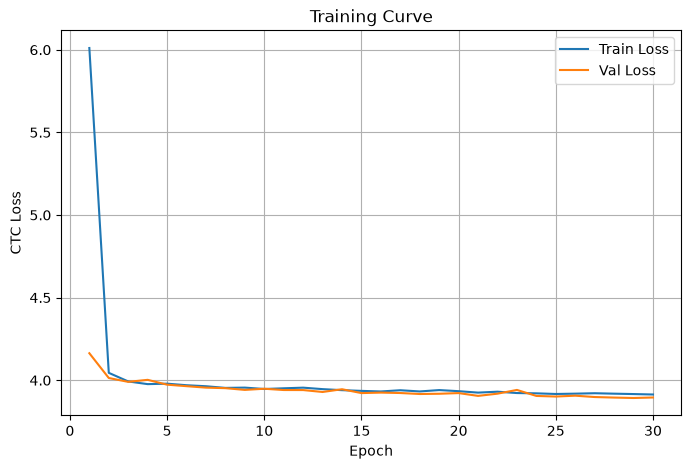

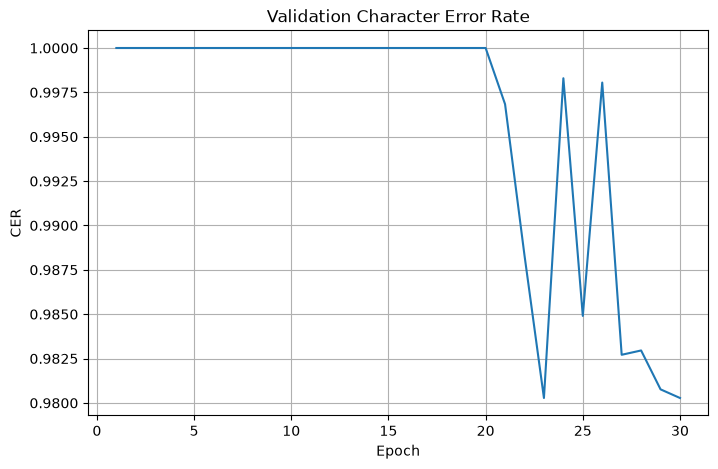

In [22]:
import matplotlib.pyplot as plt

history_df = pd.read_csv(
    HISTORY_CSV
)

plt.figure(
    figsize=(8, 5)
)

plt.plot(
    history_df["epoch"],
    history_df["train_loss"],
    label="Train Loss"
)

plt.plot(
    history_df["epoch"],
    history_df["val_loss"],
    label="Val Loss"
)

plt.xlabel("Epoch")
plt.ylabel("CTC Loss")
plt.title("Training Curve")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(
    figsize=(8, 5)
)

plt.plot(
    history_df["epoch"],
    history_df["val_cer"]
)

plt.xlabel("Epoch")
plt.ylabel("CER")
plt.title("Validation Character Error Rate")
plt.grid(True)
plt.show()

## Cell 21 — Load Best Model + Test Evaluation

In [23]:
checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location=DEVICE
)

best_model = LipReadingBaseline(
    vocab_size=VOCAB_SIZE,
    hidden_dim=GRU_HIDDEN,
    gru_layers=GRU_LAYERS,
    dropout=DROPOUT,
).to(DEVICE)

best_model.load_state_dict(
    checkpoint[
        "model_state_dict"
    ]
)

(
    test_loss,
    test_cer,
    test_preds,
    test_refs
) = evaluate(
    best_model,
    test_loader
)

print("=" * 70)
print("TEST RESULT")
print("=" * 70)

print(
    "Test Loss:",
    round(
        test_loss,
        4
    )
)

print(
    "Test CER :",
    round(
        test_cer,
        4
    )
)

eval:   0%|          | 0/56 [00:00<?, ?it/s]

TEST RESULT
Test Loss: 3.8983
Test CER : 0.9809


## Cell 22 — Test Predictions

In [24]:
for i, (
    pred,
    ref
) in enumerate(
    zip(
        test_preds,
        test_refs
    )
):

    print(
        f"[{i:03d}]"
    )

    print(
        "REF :",
        ref
    )

    print(
        "PRED:",
        pred
    )

    print(
        "-" * 70
    )

    if i >= 19:
        break

[000]
REF : ฉันคิดว่านั่นแหละ คือสิ่งที่มันควรที่จะเป็น
PRED: เ
----------------------------------------------------------------------
[001]
REF : มากันที่ Update นะคะ
PRED: เ
----------------------------------------------------------------------
[002]
REF : Update นี่หลังจาก 3 วัน
PRED: เ
----------------------------------------------------------------------
[003]
REF : เจ้าของโพสทำตามที่หลายคนแนะนำก็คือ
PRED: เ
----------------------------------------------------------------------
[004]
REF : นำข้อความนั้นไปเปิดให้แฟชายดู
PRED: 
----------------------------------------------------------------------
[005]
REF : โดยในวันนั้นนี่เธอมีนัดต่อ Lego กับเขาข้อดี
PRED: เ
----------------------------------------------------------------------
[006]
REF : ในระหว่างที่กำลังต่อ Lego ด้วยกัน
PRED: เ
----------------------------------------------------------------------
[007]
REF : เจ้าของโพสได้ยอมรับกับแฟชายตรงๆว่า
PRED: เ
----------------------------------------------------------------------
[008]


In [31]:
# ============================================================
# CTC Blank Collapse Diagnostic
# ============================================================

import torch

model.eval()

# ดูว่า model อยู่ device ไหน
DEVICE = next(model.parameters()).device
print("Model device:", DEVICE)

total_steps = 0
blank_steps = 0
nonblank_steps = 0

with torch.no_grad():

    for batch in test_loader:

        # ----------------------------------------
        # ย้าย VIDEO จาก CPU -> device เดียวกับ model
        # ----------------------------------------
        videos = batch["video"].to(DEVICE)

        # video_lengths ใช้สำหรับบอกความยาว sequence
        lengths = batch["video_lengths"]

        # Forward
        logits = model(videos, lengths)

        # เลือก class ที่มี probability สูงสุด
        pred_ids = logits.argmax(dim=-1)

        # ----------------------------------------
        # นับเฉพาะ frame จริง ไม่รวม padding
        # ----------------------------------------
        for i in range(pred_ids.size(0)):

            length = int(lengths[i].item())

            valid_pred = pred_ids[i, :length]

            total_steps += valid_pred.numel()

            blank_steps += (
                valid_pred == BLANK_ID
            ).sum().item()

            nonblank_steps += (
                valid_pred != BLANK_ID
            ).sum().item()


# ============================================================
# RESULT
# ============================================================

blank_ratio = blank_steps / total_steps
nonblank_ratio = nonblank_steps / total_steps

print("\n" + "=" * 60)
print("CTC BLANK DIAGNOSTIC")
print("=" * 60)

print(f"Total valid timesteps : {total_steps:,}")
print(f"Blank timesteps       : {blank_steps:,}")
print(f"Non-blank timesteps   : {nonblank_steps:,}")

print("-" * 60)

print(f"Blank ratio           : {blank_ratio:.4f} ({blank_ratio*100:.2f}%)")
print(f"Non-blank ratio       : {nonblank_ratio:.4f} ({nonblank_ratio*100:.2f}%)")

print("=" * 60)

Model device: cuda:0

CTC BLANK DIAGNOSTIC
Total valid timesteps : 7,810
Blank timesteps       : 7,707
Non-blank timesteps   : 103
------------------------------------------------------------
Blank ratio           : 0.9868 (98.68%)
Non-blank ratio       : 0.0132 (1.32%)


In [26]:
batch = next(iter(test_loader))

print("Batch type:", type(batch))

if isinstance(batch, dict):
    print("Batch keys:", batch.keys())
    for key, value in batch.items():
        if hasattr(value, "shape"):
            print(f"{key:20s} shape = {value.shape}")
        else:
            print(f"{key:20s} type = {type(value)}")
else:
    print(batch)

Batch type: <class 'dict'>
Batch keys: dict_keys(['video', 'video_lengths', 'targets', 'target_lengths', 'texts', 'clip_ids', 'speaker_ids'])
video                shape = torch.Size([2, 103, 1, 96, 96])
video_lengths        shape = torch.Size([2])
targets              shape = torch.Size([63])
target_lengths       shape = torch.Size([2])
texts                type = <class 'list'>
clip_ids             type = <class 'list'>
speaker_ids          shape = torch.Size([2])


# หลัง Baseline Training

ถ้า:
- Sanity loss ลด
- Full train loss ลด
- validation loss ลดบางช่วง
- model เริ่ม output ภาษาไทยบางส่วน

ถือว่า **end-to-end lip reading pipeline ทำงานแล้ว**

ขั้นถัดไปที่แนะนำ:
1. เพิ่มวิดีโอ / ผู้พูด
2. ทำ transcript correction
3. ใช้ pretrained visual speech encoder
4. เปลี่ยน BiGRU → Transformer / Conformer
5. เพิ่ม data augmentation
6. ใช้ subword tokenizer แทน character-level
7. ทำ speaker-independent split
8. ประเมิน CER / WER อย่างจริงจัง